# Gaussian-screen covariance and inference

This executed record reads cached, individually converged direct-screen
ensembles and independently calibrated toy observations. The source and beam
are fixed Gaussian profiles on an East/North tangent plane. Only the foreground
screen changes across ensemble members; each screen is shared by all
frequencies.
Readouts are beam-averaged Q and U in K. Synthetic Gaussian readout noise is
5% of unrotated polarized amplitude per sample. All frequency samples are
monochromatic; no channel response or integration time is assigned. This is
not a LuSEE sensitivity forecast or a validated Galactic residual model.

The companion script is `scripts/gaussian_screen_inference.py`; it regenerates
this notebook and all figures without launching an ensemble. Numerical products
are fingerprinted under `generated_data/gaussian_screen_inference/` and
`generated_data/cache/gaussian_screen_inference/`. The tracked compact result
record is `docs/gaussian-screen-inference-results.json`.
Run `bash scripts/run_gaussian_screen_inference.sh run` to reproduce the
bounded experiment with matching checkpoints; `status` reads its log.
Run `.venv/bin/python scripts/gaussian_screen_inference.py` to rebuild this
notebook and its figures from completed results without launching ensembles.


The five-scale covariance and separate strong-rotation gates pass. The information assessment does not support factor-of-two scale recovery with free source nuisances. 17 of 18 null acceptance checks pass. Test `1-Hc-0` at c=-0.04 rad/m² has 224/4096 false positives (5.47%), with simultaneous upper bound 6.61% above the frozen 6.5% limit. This is an unresolved calibration acceptance check. Its reported detection fractions are diagnostics for the frozen test, not a validated significance claim. No tolerance or sample count was changed after seeing these draws.

The frozen window uses 5 frequencies over 45–50 MHz. The RMS polarization phase is 1.44–1.78 rad and changes by 0.34 rad across the band; mean attenuation spans 0.207–0.356. A narrow phase change does not mean weak absolute rotation. At equal total inverse-noise-variance budget, profiling the baseline against double scale gives KL=0.352 with five samples and 0.343 with seventeen. The five-sample choice and synthetic noise were frozen before final mocks.

## Numerical and covariance validation

| ell (pc) | Screens | Maximum grid shift / unrotated P | Worst moment discrepancy / MC SE | Gate |
|---:|---:|---:|---:|:---|
| 0.05 | 128 | 5.1e-06 | 2.38 | True |
| 0.15 | 128 | 2.6e-05 | 1.60 | True |
| 0.5 | 128 | 3.5e-11 | 1.88 | True |
| 1.5 | 128 | 9e-11 | 2.32 | True |
| 5 | 128 | 5.1e-15 | 2.43 | True |

All Q/U cells, raw second moments and squared on/off differences are checked
with a screen bootstrap and a simultaneous normal diagnostic. Numerical grids
are doubled twice while the Fourier field remains fixed; cutoff truncation
retains coefficients. Domain/spectrum checks use the generator's exact discrete
covariance and tail bounds. The initial large-scale pilot failed to resolve the
source profile. The first 128-screen sweep then found coarse-grid shifts of
1.09e-4 and 1.83e-4 at ell=0.5 and 1.5 pc, respectively. These exceeded the
1e-4 criterion; both grids were doubled before the frozen experiment.
The initial ledger is retained as `covariance-validation-initial.json`.
The production grid resolves both the source profile and phase variation.
Domain enlargement changes the Fourier basis: this run checks its exact
ensemble spectral covariance and weight tails rather than comparing paired
maps from different boxes.
The normal moment diagnostic is an approximate ensemble check, not exact
coverage.


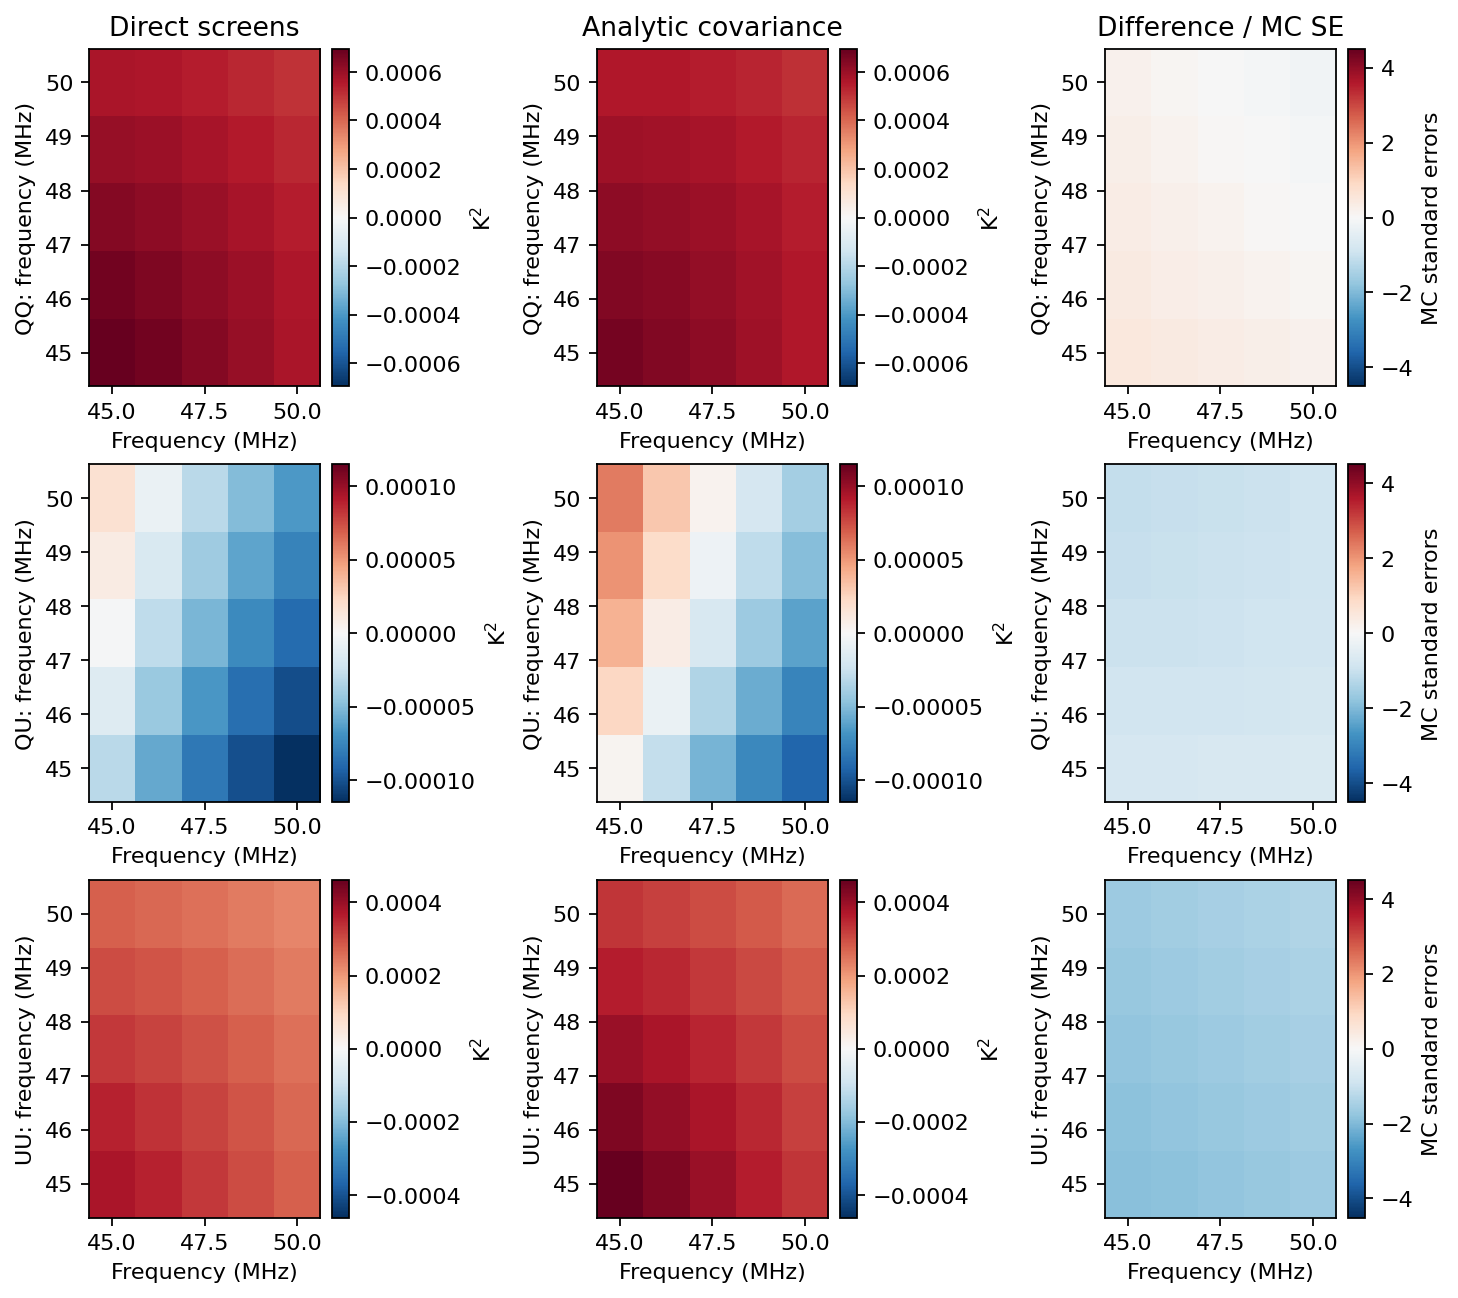

In [1]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_covariance.png'))

Joint covariance from the 128-screen baseline ensemble at 45–50 MHz, with correlation length 0.5 pc at 100 pc. Direct estimates and analytic predictions share scales within each row; residuals divide by bootstrap Monte Carlo standard errors. These are screen-sampling errors, not radiometer noise. All cells, including Q–U cross terms, enter the gate.

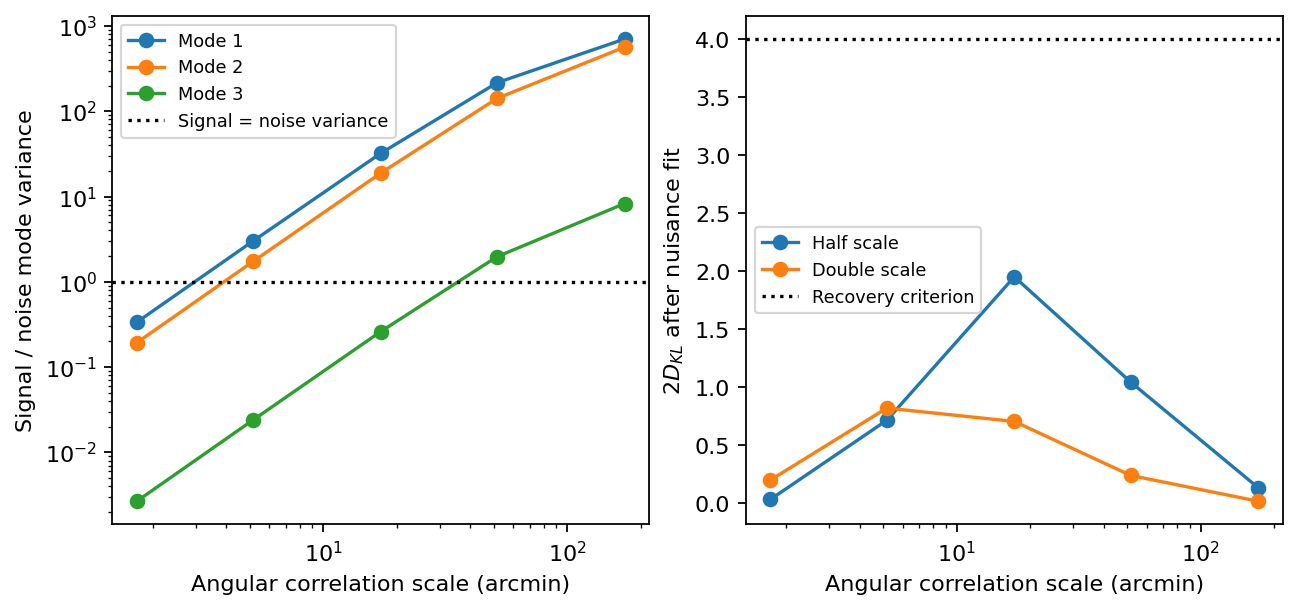

In [2]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_information.png'))

Expected Gaussian-model information at five frequencies in 45–50 MHz with independent synthetic noise of 5% of unrotated polarized amplitude per Q/U sample. Left: the three largest generalized covariance modes. Right: twice the Kullback–Leibler divergence to half/double correlation length after profiling amplitude, angle and spectral index. The line marks the declared design criterion, not a frequentist significance. No tested scale separates both alternatives by that criterion.

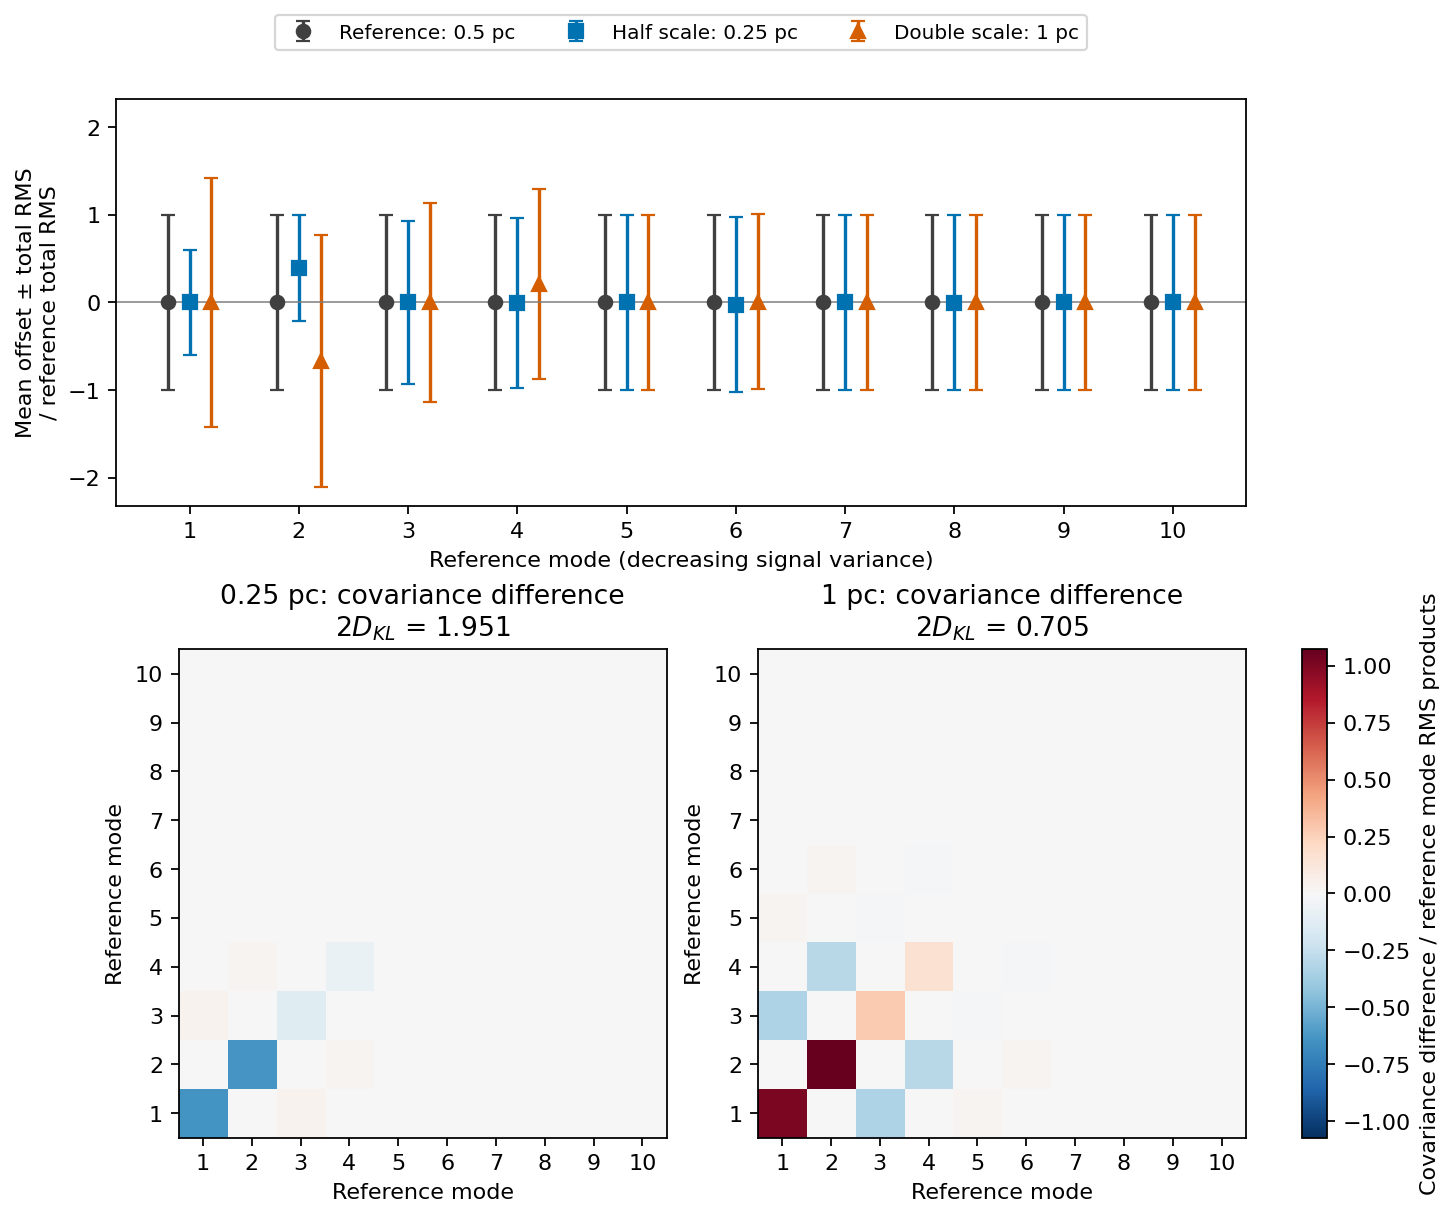

In [3]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_mode_comparison.png'))

### Figure 2b: what the fitted scale alternatives change

The baseline is $\ell=0.5$ pc at 100 pc, using the same five frequencies
over 45–50 MHz and synthetic noise as Figure 2. The half-scale and double-scale
models use the converged amplitude/angle/spectral-index fits saved in
`assessment.json`; no new optimization or screen draws enter this figure.

Write the ten measurements as
$\mathbf y=(Q_1,\ldots,Q_5,U_1,\ldots,U_5)^T
=\boldsymbol\mu+\mathbf s+\mathbf n$.
The centered screen fluctuation has covariance $S=E[\mathbf s\mathbf s^T]$
and synthetic readout noise has covariance $N=E[\mathbf n\mathbf n^T]$.
Thus “signal” in Figure 2's left panel means $S$, excluding the ensemble mean.
For orthonormal eigenvectors
$$N^{-1/2}S_0N^{-1/2}\mathbf v_a=\lambda_a\mathbf v_a,$$
the mode $z_a=\mathbf v_a^TN^{-1/2}(\mathbf y-\boldsymbol\mu_0)$ has
reference signal variance $\lambda_a$, noise variance one, and total variance
$1+\lambda_a$. Subscript 0 denotes the reference model. Modes are ordered by
decreasing $\lambda_a$; all ten are retained, including noise-dominated modes.

For display, divide each mode by its reference total RMS:
$$W_{a:}=\frac{\mathbf v_a^TN^{-1/2}}{\sqrt{1+\lambda_a}},\qquad
\mathbf t=W(\mathbf y-\boldsymbol\mu_0).$$
The reference has mean zero and covariance $I$. An alternative has
$$\mathbf m=W(\boldsymbol\mu_{\rm alt}-\boldsymbol\mu_0),\qquad
C=W(S_{\rm alt}+N)W^T.$$
The source fit transforms both the mean and screen covariance; the readout
noise $N$ stays fixed. The upper panel shows $m_a\pm\sqrt{C_{aa}}$ alongside
the reference $0\pm1$. Bars are ensemble RMS including readout noise, not
errors on fitted parameters or confidence intervals. The lower panels show
$C-I$: diagonal entries measure variance changes, and off-diagonal entries
show correlations between reference modes introduced by the alternative.
Both matrices share one signed colour scale. All models use the same reference
basis; separately diagonalizing each alternative would hide these correlations.

At this baseline, the alternatives change the first two mode variances and
shift the second mode's mean. The double-scale model also introduces
correlations with modes 3 and 4. The models therefore predict different
distributions, although their marginal RMS ranges overlap. These differences
remain below the declared information criterion after the source fit.

The overlapping marginal RMS bars make the comparison tangible but do not
define a detection or recovery test. The covariance panels retain information
that those bars omit. Because $W$ is invertible, this full ten-mode comparison
preserves the Gaussian-model KL divergence in Figure 2 exactly; the builder
checks it against the saved values. Gaussian distributions here are the
information assessment's approximation, not an assumption established by
matching first and second moments. The plotted RMS follows from those moments
even if the screen readouts are non-Gaussian.


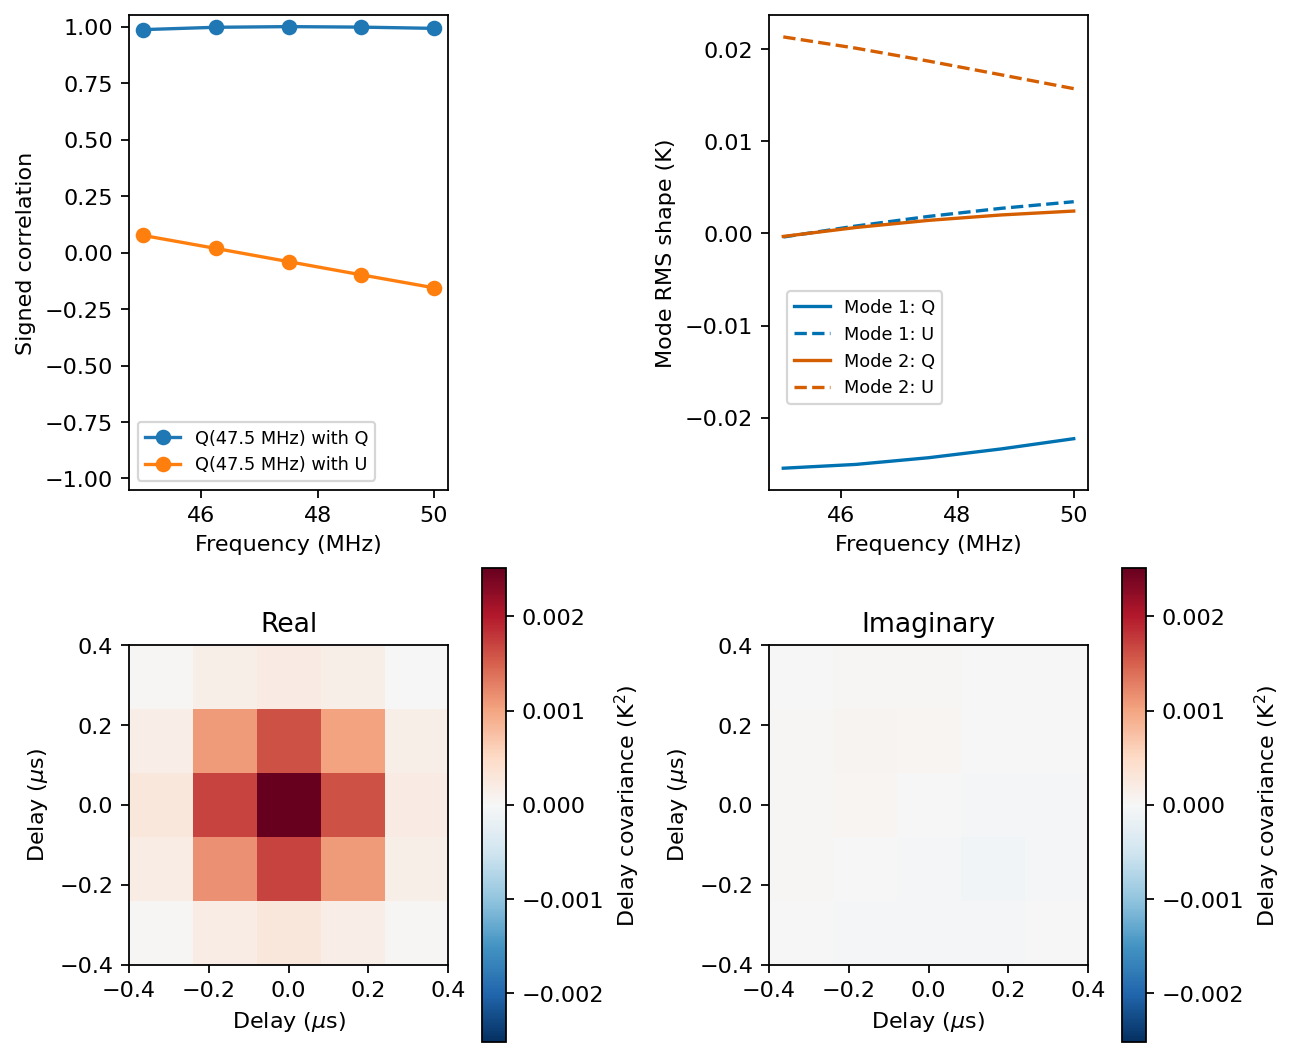

In [4]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_modes.png'))

Baseline analytic covariance on the same five-frequency grid. The reference slice retains signed Q–U correlations. Mode shapes include their RMS amplitudes in K relative to the declared synthetic noise. Delay covariance uses a Hann window normalized by sqrt(sum(window²)) on both axes, with the displayed complex P=Q+iU convention. Both real and imaginary off-diagonal structure are retained; five samples provide only a coarse delay representation. This is centered power; the notebook also records the transformed-mean contribution to raw delay power.

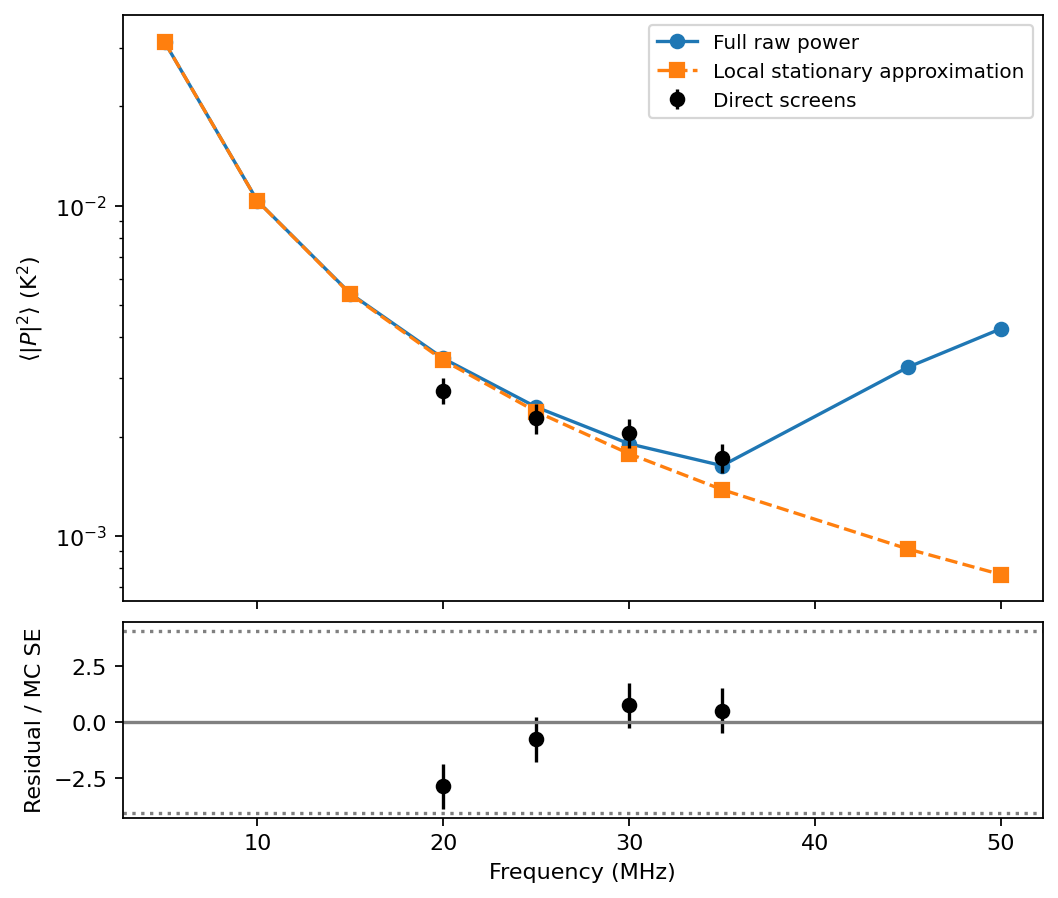

In [5]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_template.png'))

Physical polarization power for the baseline source/beam/screen. Direct-screen points use 128 independent, individually converged realizations at 20–35 MHz; their errors are screen Monte Carlo errors. The local small-separation approximation supplies its own physical amplitude and approaches the full expression toward strong rotation. The residual panel compares direct sums with the full prediction. Curves below 20 MHz have reduced-integral checks but no direct-screen validation in this run. Narrow-band covariance-shape errors are tabulated separately.

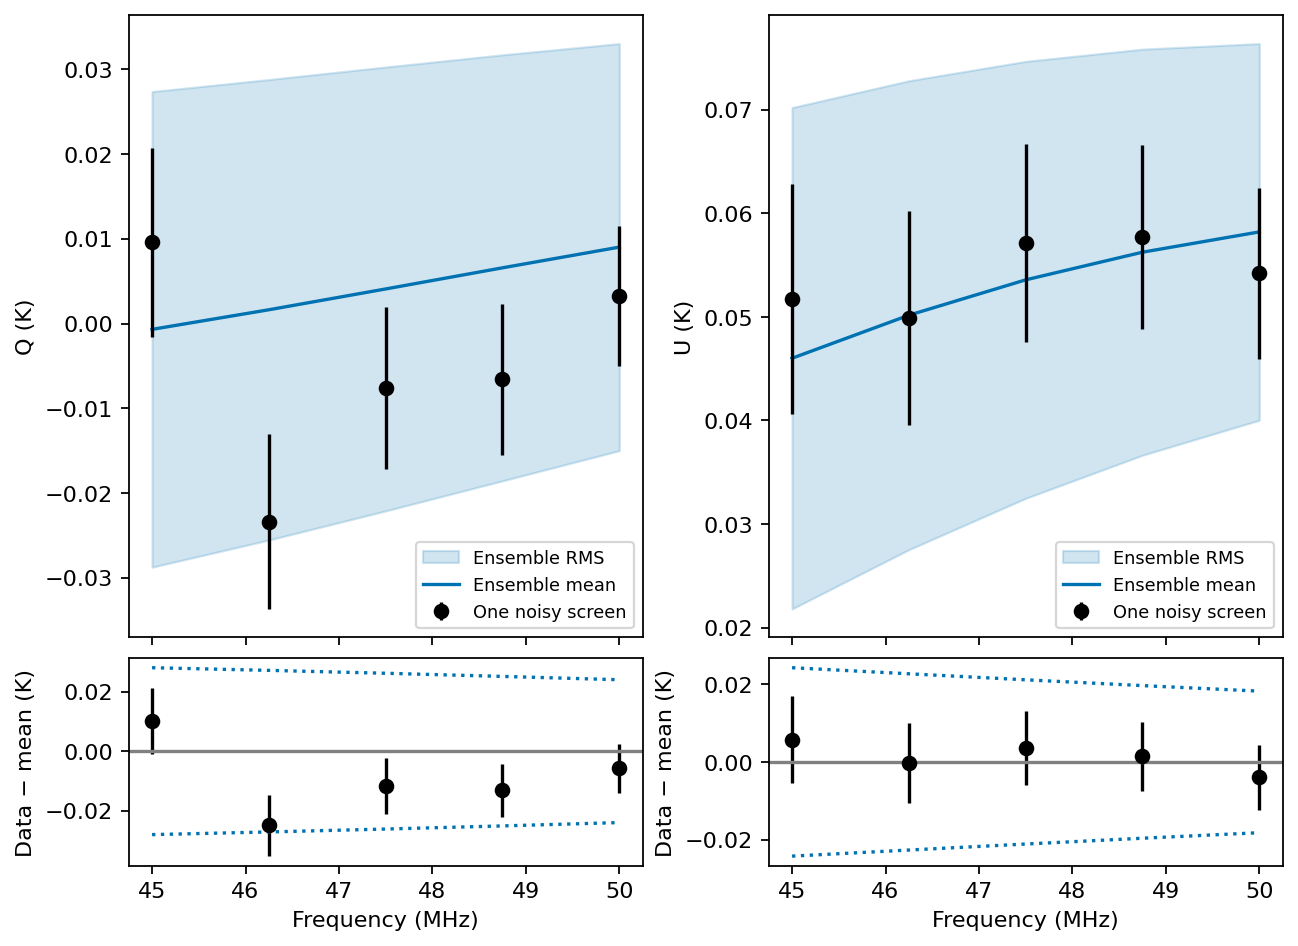

In [6]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_observation.png'))

The first final-validation screen at ell=0.5 pc, chosen by seed order, with independent synthetic readout noise. Error bars show that noise; the band and dotted residual curves show total ensemble RMS, not a confidence interval for this particular hidden screen. The inference receives Q/U alone and never the paired Faraday-off realization.

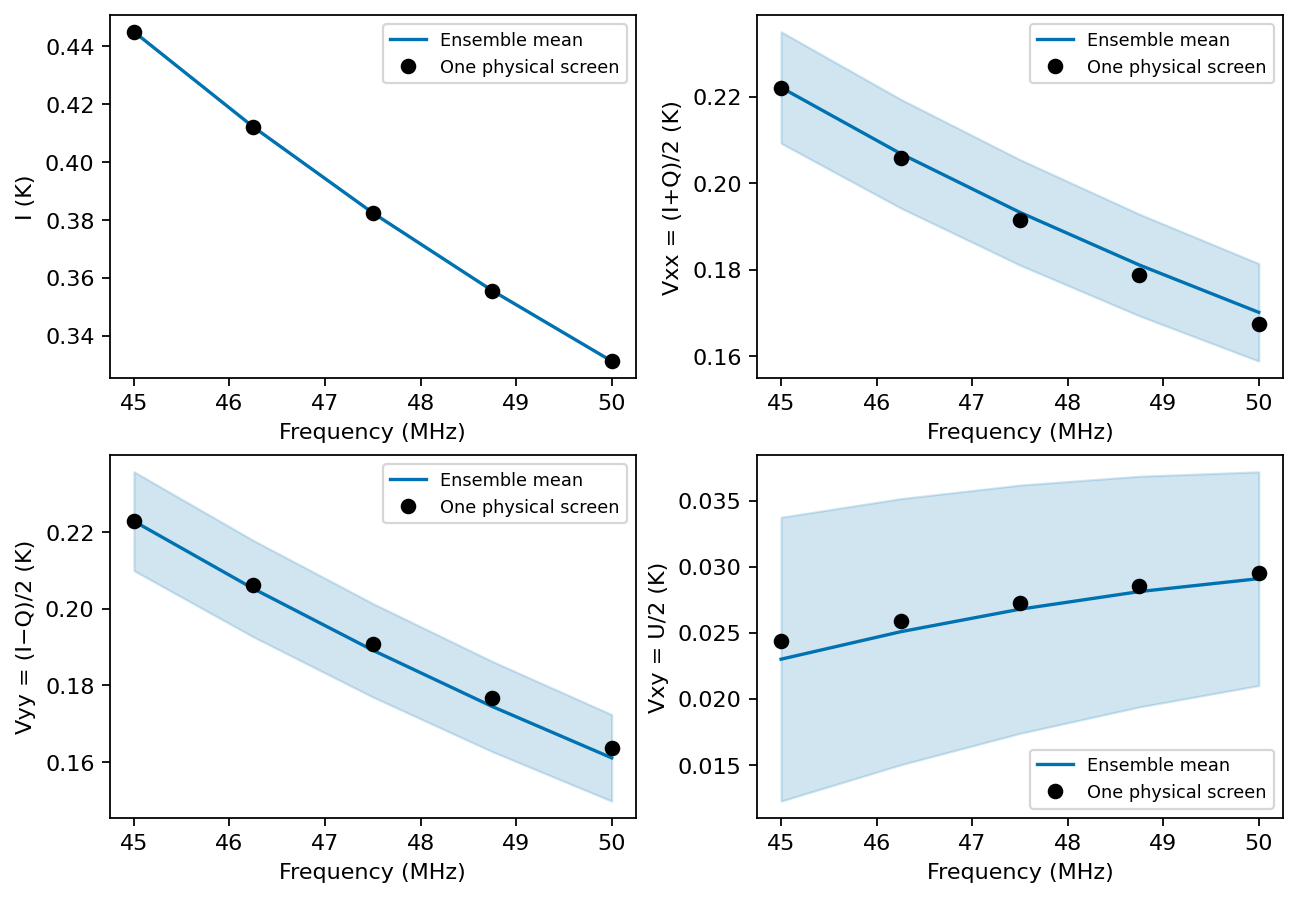

In [7]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_readouts.png'))

Ideal x/y products from the same first physical final-validation screen, before synthetic readout noise. I is deterministic. The bands show screen RMS about each ensemble mean. Vxx, Vyy and Vxy are algebraic displays of I/Q/U, not extra independent observations; only the nonredundant joint Q/U vector enters inference.

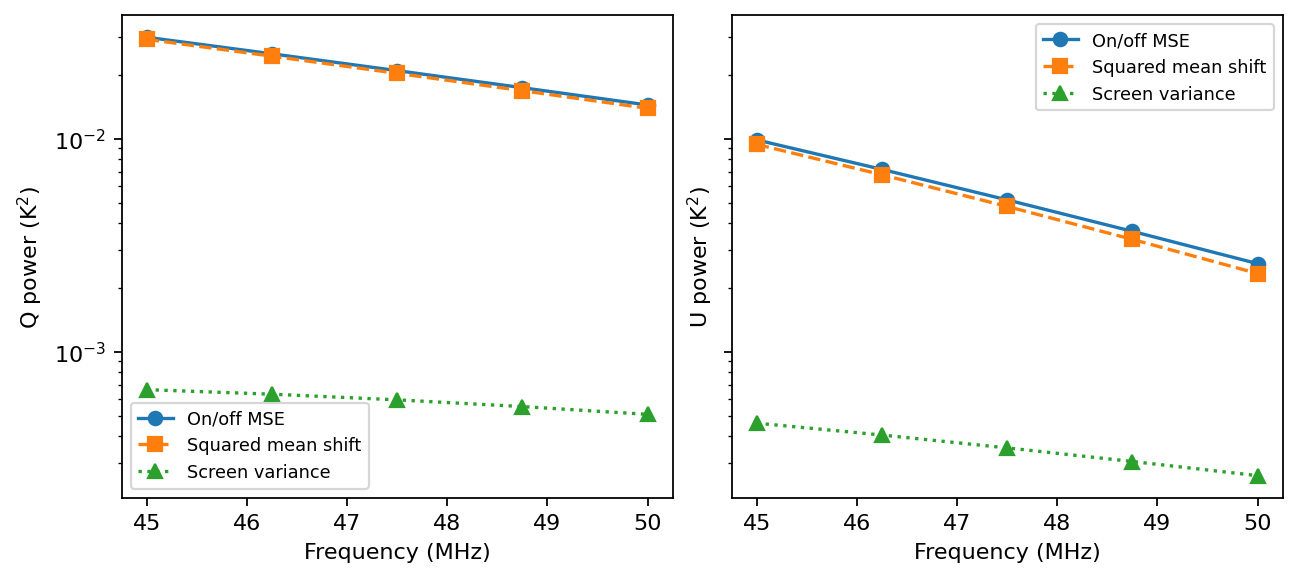

In [8]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_mse.png'))

Baseline paired on/off mean-square difference decomposed into the squared ensemble mean shift and centered screen variance at 45–50 MHz. All terms use the same beam-averaged K reference plane. This retains the original diagnostic; hidden per-screen off truth is not provided to any detection test.

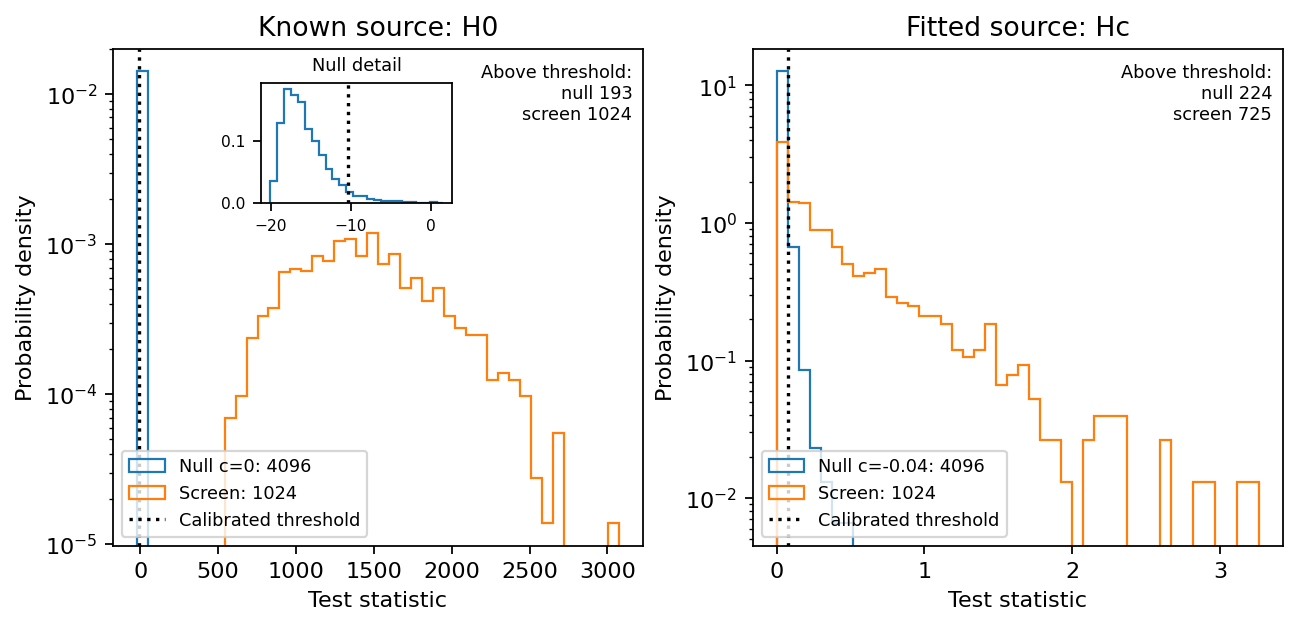

In [9]:
from IPython.display import Image, display
display(Image(filename='report/figures/gaussian_inference_detection.png'))

Held-out null and ell=0.5 pc screen statistics with thresholds fixed on separate calibration draws. Left: twice the maximum Gaussian log-likelihood difference over 41 scales against zero rotation with known source. Right: covariance-weighted residual discrepancy after fitting a constant-depth screen and source amplitude, angle and beta. It has an empirical null distribution, with no assumed chi-square law. Displayed counts are final-validation outcomes. Each panel shows the tested null depth with the largest false-positive upper bound. The Hc threshold is the largest of three calibration quantiles. The inset resolves the narrow known-source null distribution. The fitted-beta full-covariance Hc statistic fails the frozen null acceptance check; this panel reports its outcome without claiming validated false-positive control.

## What the physical template comparison establishes

The existing `noise.faraday_signal_covariance` on template commit
`adb40246a56965ea1b7247fe1865771c8a939384` uses the signed, unit-normalized
depth-power transform $S(x,x')=\int d\phi\,\widehat H(\phi)
\exp[2i\phi(x-x')]$. For Gaussian $\widehat H$ with mean m and variance
$\sigma_\phi^2$, its shape is the numerator below. This comparison uses that
Gaussian toy depth distribution, not the saved Galactic histogram.

For x=lambda², small-separation Gaussian-screen coherence gives the raw
same-branch kernel proportional to

$$\frac{\exp[2im(x-x')-2\sigma_\phi^2(x-x')^2]}
{1+8\sigma_\phi^2w^2xx'/\ell^2}.$$

Freezing xx' at the band center produces the stationary template. In strong
rotation, mean and opposite-branch terms are negligible; this limit is checked
against the full covariance, rather than imposed at all frequencies. The
normalization comes from physical source/beam/screen scales. A freely fitted
normalization is shown separately to isolate shape error. The absolute
polarization-power normalization at reference x0 is
$\eta^2 P_{\rm ref}^2/[1+8\sigma_\phi^2w^2x_0^2/\ell^2]$, multiplied by the
source spectral factors on both frequency axes. No numerical pixel area enters.
The Q/U assembly retains both branches; the approximation sets the relation
moment and mean to zero only as a tested strong-rotation limit.

| Band (MHz) | Max diagonal relative error | Max correlation error | Fitted covariance relative error |
|---|---:|---:|---:|
| 45–50 | 0.384 | 0.107 | 0.25 |
| 25–35 | 1.01 | 0.0039 | 0.351 |
| 29.9–30.1 | 0.0804 | 8.68e-06 | 0.0062 |
| 19.9–20.1 | 0.0323 | 2.46e-06 | 0.00878 |
| 9.9–10.1 | 0.0402 | 1.66e-07 | 0.0189 |

| Band (MHz) | Fitted power multiplier | Whitened mean error | Whitened covariance error |
|---|---:|---:|---:|
| 45–50 | 1.12 | 3.43 | 0.366 |
| 25–35 | 0.833 | 0.14 | 0.308 |
| 29.9–30.1 | 1.07 | 0.00696 | 0.0546 |
| 19.9–20.1 | 1.01 | 1.3e-16 | 0.00704 |
| 9.9–10.1 | 1 | 0 | 0.000537 |

Whitened errors use the full model's S+N: Euclidean norm for the omitted
mean and spectral norm for covariance error. The 17-point comparisons keep
the same total inverse-noise-variance budget as the five-point benchmark.
Diagonal errors
use absolute physical amplitude; the fitted multiplier is applied only in the
separate Frobenius-norm shape comparison.

These are conditional toy comparisons. The arbitrary depth histogram in the
existing real-sky template does not inherit this normalization or covariance
validity. The 9.9–10.1 MHz row has reduced-integral validation only.


## Calibrated detection and limitations

Test names `known-0`, `0-Hc-0`, `1-Hc-0`, `1-Hc-1` denote known-source
likelihood scoring, fitted amplitude/angle against a constant-depth screen,
additionally fitted beta, and the last test with cross-frequency signal
covariance removed. The ablation retains same-frequency Q–U covariance and
uses the same physical draws and unchanged noise. Each statistic has its own
null calibration. Adding nuisance freedom changes both the residual statistic
and its null threshold; detection fractions need not decrease monotonically.
H0 in a test name
substitutes zero rotation for Hc, with
the same source nuisance freedom. Detection of zero-rotation departures and
of constant-screen
departures are distinct conclusions.

| Ensemble | ell (pc) | Test | Detection fraction | Simultaneous interval |
|---|---:|---|---:|---|
| final-validation | 0.5 | 0-H0-0 | 0.513 | [0.463, 0.562] |
| final-validation | 0.5 | 0-Hc-0 | 0.363 | [0.317, 0.412] |
| final-validation | 0.5 | 1-H0-0 | 0.512 | [0.462, 0.561] |
| final-validation | 0.5 | 1-Hc-0 | 0.708 | [0.662, 0.752] |
| final-validation | 0.5 | 1-Hc-1 | 0.176 | [0.140, 0.216] |
| final-validation | 0.5 | known-0 | 1.000 | [0.993, 1.000] |
| final-validation | 1.5 | 0-H0-0 | 0.657 | [0.609, 0.703] |
| final-validation | 1.5 | 0-Hc-0 | 0.370 | [0.323, 0.419] |
| final-validation | 1.5 | 1-H0-0 | 0.607 | [0.558, 0.655] |
| final-validation | 1.5 | 1-Hc-0 | 0.461 | [0.412, 0.511] |
| final-validation | 1.5 | 1-Hc-1 | 0.112 | [0.083, 0.146] |
| final-validation | 1.5 | known-0 | 1.000 | [0.993, 1.000] |
| mixture-validation | 0.5 | 0-H0-0 | 0.463 | [0.414, 0.512] |
| mixture-validation | 0.5 | 0-Hc-0 | 0.286 | [0.243, 0.332] |
| mixture-validation | 0.5 | 1-H0-0 | 0.459 | [0.410, 0.509] |
| mixture-validation | 0.5 | 1-Hc-0 | 0.538 | [0.488, 0.587] |
| mixture-validation | 0.5 | 1-Hc-1 | 0.121 | [0.091, 0.156] |
| mixture-validation | 0.5 | known-0 | 1.000 | [0.993, 1.000] |

The simultaneous null-calibration gate passed:
**False**.
Null rates apply only at the declared source amplitude/angle/spectral index
and constant depths −0.04, 0, +0.04 rad/m²; fitted nuisance ranges do not imply
uniform calibration throughout those ranges. Noise is independent across Q/U
and frequency in this controlled experiment.

The finite-model assessment does not support factor-of-two scale recovery
with the declared noise and free source nuisances. No confidence intervals for
correlation length are claimed. The mean is independent of ell; at small ell/w,
covariance amplitude scales approximately as P_ref²(ell/w)². Changing source
width while holding ell/w and beam-diluted polarized amplitude fixed gives an
exact ambiguity in Q/U alone; additional intensity constraints could help.

The scale-mixture stress test uses A²=0.5 or 1.5 with equal probability,
independently per screen: E[A²]=1 preserves ensemble RM covariance. Its phase
statistics need not match Gaussian depths. Comparison with the conditional
mixture moments separates physical misspecification from non-Gaussian readout
likelihood effects. Gaussian scores here are empirically calibrated statistics;
whitened residual diagnostics alone do not establish a Gaussian likelihood.


## Calibration precision and numerical stability

Each depth has 4096 threshold-calibration draws and 4096 independent validation draws. The threshold is the 95th percentile (higher order statistic); Hc uses the maximum across three depths. Exact binomial intervals use a Bonferroni correction across 18 null comparisons. The acceptance requirement is an upper bound at or below 0.065. This tests control of false positives; a conservative rate can be lower than the nominal 0.05.

| Test | Null depth (rad/m²) | False-positive fraction | Simultaneous interval | Nuisance boundary fraction |
|---|---:|---:|---|---:|
| 0-H0-0 | 0 | 209/4096 (0.051) | [0.041, 0.062] | 0.000 |
| 0-H0-1 | 0 | 188/4096 (0.046) | [0.037, 0.057] | 0.000 |
| 0-Hc-0 | -0.04 | 196/4096 (0.048) | [0.038, 0.059] | 0.000 |
| 0-Hc-0 | 0 | 80/4096 (0.020) | [0.014, 0.027] | 0.000 |
| 0-Hc-0 | 0.04 | 113/4096 (0.028) | [0.021, 0.036] | 0.000 |
| 0-Hc-1 | -0.04 | 159/4096 (0.039) | [0.030, 0.049] | 0.000 |
| 0-Hc-1 | 0 | 176/4096 (0.043) | [0.034, 0.053] | 0.000 |
| 0-Hc-1 | 0.04 | 151/4096 (0.037) | [0.029, 0.047] | 0.000 |
| 1-H0-0 | 0 | 198/4096 (0.048) | [0.039, 0.059] | 0.025 |
| 1-H0-1 | 0 | 158/4096 (0.039) | [0.030, 0.048] | 0.025 |
| 1-Hc-0 | -0.04 | 224/4096 (0.055) | [0.045, 0.066] | 0.023 |
| 1-Hc-0 | 0 | 19/4096 (0.005) | [0.002, 0.009] | 0.026 |
| 1-Hc-0 | 0.04 | 20/4096 (0.005) | [0.002, 0.009] | 0.024 |
| 1-Hc-1 | -0.04 | 170/4096 (0.042) | [0.033, 0.052] | 0.023 |
| 1-Hc-1 | 0 | 173/4096 (0.042) | [0.033, 0.052] | 0.026 |
| 1-Hc-1 | 0.04 | 178/4096 (0.043) | [0.035, 0.054] | 0.024 |
| known-0 | 0 | 193/4096 (0.047) | [0.038, 0.058] | 0.000 |
| known-1 | 0 | 175/4096 (0.043) | [0.034, 0.053] | 0.000 |

Before taking the maximum over depths, the calibration quantile's tail-probability interval is [0.040, 0.061] with the same simultaneous correction. Boundary fractions include the physical polarization cap, fitted beta and fitted constant-depth bounds; the tracked record separates these.

Re-evaluating every final statistic on the preceding angular grid changed 0 decisions across the 30 reported tests. Maximum changes are recorded per test; the frozen tolerance is 0.001 times max(1, absolute threshold) and at most one decision per test. No covariance jitter or eigenvalue clipping is used. The source-profiled tests fit each null and use a fixed ell=0.5 pc covariance-weighted residual discrepancy. They are empirically calibrated tests, not a claimed profile likelihood ratio between Hs and Hc. Full Hs nuisance-likelihood intervals were not pursued after the information gate rejected scale recovery.

## Dependence on source restrictions

| Ensemble | ell (pc) | Null | Beta boundary fraction | Depth boundary fraction |
|---|---:|---|---:|---:|
| final-validation | 0.5 | H0 | 0.894 | 0.000 |
| final-validation | 0.5 | Hc | 0.896 | 0.005 |
| final-validation | 1.5 | H0 | 0.656 | 0.000 |
| final-validation | 1.5 | Hc | 0.637 | 0.021 |
| mixture-validation | 0.5 | H0 | 0.783 | 0.000 |
| mixture-validation | 0.5 | Hc | 0.775 | 0.026 |

Frequent beta-boundary hits show that detection is conditional on the frozen intrinsic spectral-index interval [-4, -1]. Rejection of these fitted nulls does not exclude a source with a more flexible intrinsic spectrum. The table reports every final ensemble; a larger source model requires a separately frozen calibration.

The mixture's measured RM covariance agrees within 1.15 sampling standard errors at separations 0, 0.5, 1 and 2 times ell. Each screen retains its drawn amplitude; none is renormalized.

## Distribution and matched-covariance stress test

| Ensemble | ell (pc) | Max absolute whitened skew | Max absolute excess kurtosis | Max 3σ tail fraction |
|---|---:|---:|---:|---:|
| final-validation | 0.5 | 0.12 | 0.38 | 0.003 |
| final-validation | 1.5 | 0.39 | 0.61 | 0.006 |
| mixture-validation | 0.5 | 0.15 | 1.17 | 0.115 |

These diagnostic maxima are descriptive and correlated; no normal-tail significance is assigned. Coverage of scale intervals is not claimed. The mixture rows are whitened with the Gaussian-screen prediction, so they include physical model mismatch.

For the mixture's full moments, the worst Gaussian-screen residual is 30.46 MC standard errors against the simultaneous threshold 4.16. Conditioning on A instead gives 1.89; its moment gate passes: **True**. The analytic physical mismatch has whitened mean norm 0.652 and covariance spectral norm 3.426, using Gaussian S+N. Matching RM two-point covariance therefore does not by itself fix the observable phase moments. The detection fractions above quantify this one stress test, without establishing robustness to general non-Gaussian or Galactic screens.

In [10]:
import json
from pathlib import Path
path = Path('docs/gaussian-screen-inference-results.json')
record = json.loads(path.read_text())
print(json.dumps({'scope': record['scope'], 'inputs': record['manifest']['input_sha256'], 'null_calibration_passed': record['null_calibration_passed']}, indent=2))

{
  "scope": "conditional toy benchmark; source-known likelihood and source-profiled discrepancy tests; no radiometer forecast",
  "inputs": {
    "covariance-validation": "0fe8834c75303f7482576c84a8dd8a0c9edb36888df8a2274878de3e30dc8c00",
    "strong-validation": "76d114d35dc262da135b87d11e540eeeca48ab49462f17af73fbd1c24f85db09",
    "assessment": "e375542c703c76bcb1bbca7ef8c500e345aaeaaf2079db240a6f27ef4eedc5b7",
    "inference-results": "e491841debcb9f2bdec0066a7a56d95ae7007b7fe354beb041734586df80ace6",
    "final-validation": "4354a90e63c24c4f65320a14c19f8bdfe1ebaec50ca259b86701d3ae63fe78b8",
    "mixture-validation": "a262b51717d784283a4c71df3f90242b3ba9dc13a285a3cc658d27b157a957d8"
  },
  "null_calibration_passed": false
}
